In [1]:
import sys; sys.path.append("..")
from src.data import make_series
s = make_series()
print(len(s), s.index[0], s.index[-1])

8064 2026-01-01 00:00:00 2026-01-28 23:55:00


<Axes: >

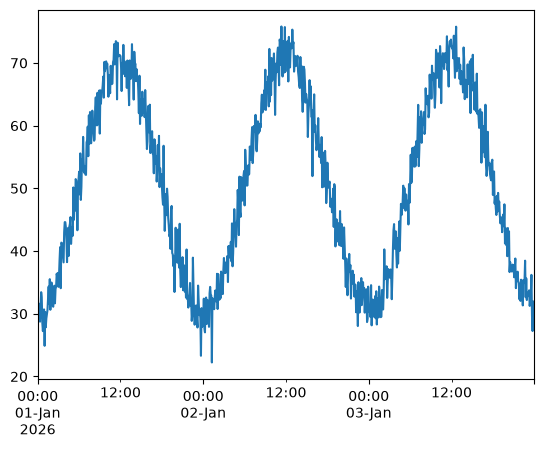

In [2]:
s.iloc[:3*288].plot()

43


<Axes: >

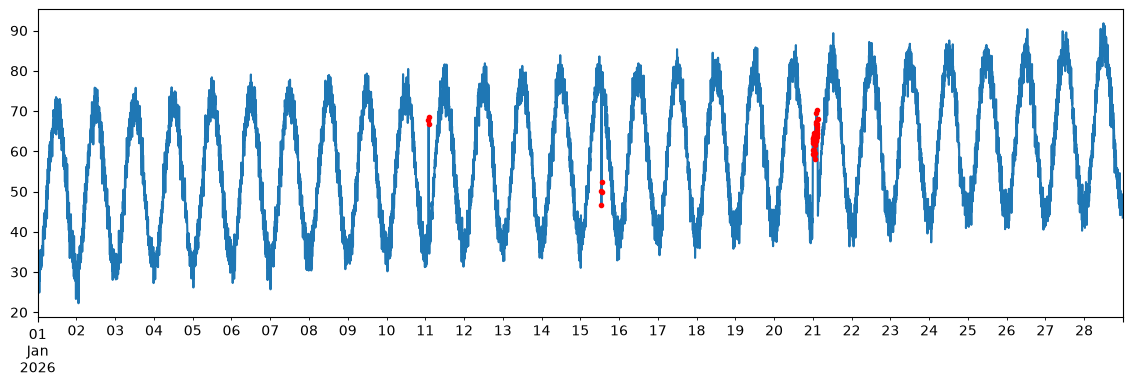

In [3]:
import sys; sys.path.append("..")
from src.data import make_series, inject_anomalies

s = make_series()
anoms = [(10*288 + 2*12, 3, 30), (14*288 + 13*12, 4, -30), (20*288 + 0*12, 36, 20)]

s2, labels = inject_anomalies(s, anoms)
print(labels.sum())  # should print 43

ax = s2.plot(figsize=(14, 4))
s2[labels].plot(ax=ax, style="r.")

In [4]:
import sys; sys.path.append("..")
from src.data import make_series, inject_anomalies
from src.detectors import static_threshold_scores

s = make_series()
anoms = [(10*288 + 2*12, 3, 30), (14*288 + 13*12, 4, -30), (20*288 + 0*12, 36, 20)]
s2, labels = inject_anomalies(s, anoms)

train_end = 7 * 288
scores = static_threshold_scores(s2, train_end)

for k in [1.5, 2, 2.5, 3]:
    flags = scores > k
    print(k, "flagged:", flags.sum(), "| anomaly points caught:", (flags & labels).sum(), "of", labels.sum())

1.5 flagged: 1608 | anomaly points caught: 0 of 43
2 flagged: 460 | anomaly points caught: 0 of 43
2.5 flagged: 17 | anomaly points caught: 0 of 43
3 flagged: 0 | anomaly points caught: 0 of 43


In [5]:
import sys; sys.path.append("..")
import numpy as np
from src.evaluate import event_metrics

labels = np.zeros(1000, bool)
labels[200:211] = True
labels[500:506] = True
flags = np.zeros(1000, bool)
flags[203] = True        # hits the first window
flags[700:703] = True    # false alarm
flags[50] = True         # inside the training period, must be ignored

print(event_metrics(flags, labels, train_end=100, per_day=288))

{'events': 2, 'precision': 0.5, 'recall': np.float64(0.5), 'f1': np.float64(0.5), 'false_alarms_per_day': 0.32}


In [6]:
import pandas as pd
rows = []
for k in [1.5, 2, 2.5, 3]:
    m = event_metrics(scores > k, labels, train_end, per_day=288)
    rows.append({"k": k, **m})
pd.DataFrame(rows).round(3)

,k,events,precision,recall,f1,false_alarms_per_day
0,1.5,30,0.0,0.0,0.0,1.429
1,2.0,32,0.0,0.0,0.0,1.524
2,2.5,6,0.0,0.0,0.0,0.286
3,3.0,0,0.0,0.0,0.0,0.000
